<a href="https://colab.research.google.com/github/yeyevtushenko/Methods-and-Technologies-of-Computational-Intelligence/blob/main/%D0%9C%D0%B5%D1%82%D0%BE%D0%B4%D0%B8_%D1%82%D0%B0_%D1%82%D0%B5%D1%85%D0%BD%D0%BE%D0%BB%D0%BE%D0%B3%D1%96%D1%97_%D0%BE%D0%B1%D1%87%D0%B8%D1%81%D0%BB%D1%8E%D0%B2%D0%B0%D0%BB%D1%8C%D0%BD%D0%BE%D0%B3%D0%BE_%D1%96%D0%BD%D1%82%D0%B5%D0%BB%D0%B5%D0%BA%D1%82%D1%83_%D0%97%D0%9A_61%D0%9F%D0%9C_%D0%84%D0%B2%D1%82%D1%83%D1%88%D0%B5%D0%BD%D0%BA%D0%BE_%D0%B1%D0%B0%D0%B7%D0%BE%D0%B2%D0%B8%D0%B9_%D0%9B%D0%B0%D0%B1%E2%84%967.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Імпорт бібліотек

In [ ]:
import random

import numpy as np
import pandas as pd
import torch
import matplotlib
import matplotlib.pyplot as plt
import sklearn.datasets
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

matplotlib.rcParams['figure.figsize'] = (10.0, 8.0)

random.seed(0)
np.random.seed(0)
torch.manual_seed(0)
torch.cuda.manual_seed(0)
torch.backends.cudnn.deterministic = True

# Завдання 1. Покращення нейронної мережі для класифікації вин

> Спробувати поліпшити результат нейронної мережі, що надана в теоретичній частині, а саме:
>
> a) Оптимізуйте архітектуру нейронної мережі.
>
> b) Спробуйте змінити кількість прихованих шарів
>
> c) Змінити оптимізатор.
>
> d) Змінити Learning rate.
>
> e) Змінити функцію активації.
>
> f) Спробуйте використати весь набір ознак (зараз ми використовували лише 2 ознаки для простої візуалізації)
>
> g) Спробуйте інші поліпшення/зміни.

## Вихідна мережа з теоретичної частини

In [ ]:
wine = sklearn.datasets.load_wine()
print(wine.data.shape)
print(wine.feature_names)
print(wine.target_names)

X_train, X_test, y_train, y_test = train_test_split(
    wine.data[:, :2],
    wine.target,
    test_size=0.3,
    shuffle=True)

X_train = torch.FloatTensor(X_train)
X_test = torch.FloatTensor(X_test)
y_train = torch.LongTensor(y_train)
y_test = torch.LongTensor(y_test)

print(X_train.shape, X_test.shape)

(178, 13)
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
['class_0' 'class_1' 'class_2']
torch.Size([124, 2]) torch.Size([54, 2])


Набір містить 178 пляшок вина з 13 параметрами та три класи. Для простої візуалізації в теорії використовуються лише дві перші ознаки (`alcohol` та `malic_acid`), а 30% даних відводиться на тест.

In [ ]:
class WineNet(torch.nn.Module):
    def __init__(self, n_hidden_neurons):
        super(WineNet, self).__init__()

        self.fc1 = torch.nn.Linear(2, n_hidden_neurons)
        self.activ1 = torch.nn.Sigmoid()
        self.fc2 = torch.nn.Linear(n_hidden_neurons, n_hidden_neurons)
        self.activ2 = torch.nn.Sigmoid()
        self.fc3 = torch.nn.Linear(n_hidden_neurons, 3)
        self.sm = torch.nn.Softmax(dim=1)

    def forward(self, x):
        x = self.fc1(x)
        x = self.activ1(x)
        x = self.fc2(x)
        x = self.activ2(x)
        x = self.fc3(x)
        return x

    def inference(self, x):
        x = self.forward(x)
        x = self.sm(x)
        return x

wine_net = WineNet(5)

loss = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(wine_net.parameters(), lr=1.0e-3)

batch_size = 10
baseline_accuracy = []

for epoch in range(5000):
    order = np.random.permutation(len(X_train))
    for start_index in range(0, len(X_train), batch_size):
        optimizer.zero_grad()

        batch_indexes = order[start_index:start_index + batch_size]

        x_batch = X_train[batch_indexes]
        y_batch = y_train[batch_indexes]

        preds = wine_net.forward(x_batch)

        loss_value = loss(preds, y_batch)
        loss_value.backward()

        optimizer.step()

    if epoch % 100 == 0:
        test_preds = wine_net.forward(X_test)
        test_preds = test_preds.argmax(dim=1)
        baseline_accuracy.append((test_preds == y_test).float().mean().item())

print("Точність на тесті кожні 500 епох:", [round(a, 3) for a in baseline_accuracy[::5]])
print("Точність після 5000 епох:", baseline_accuracy[-1])

Точність на тесті кожні 500 епох: [0.407, 0.407, 0.5, 0.685, 0.685, 0.759, 0.815, 0.833, 0.852, 0.852]
Точність після 5000 епох: 0.8518518805503845


Це точна реалізація навчання з теорії: два приховані шари по 5 нейронів із сигмоїдою, Adam зі швидкістю навчання 1e-3, батчі по 10 елементів і 5000 епох. Точність на тесті рахується кожні 100 епох через `argmax` виходів без softmax.

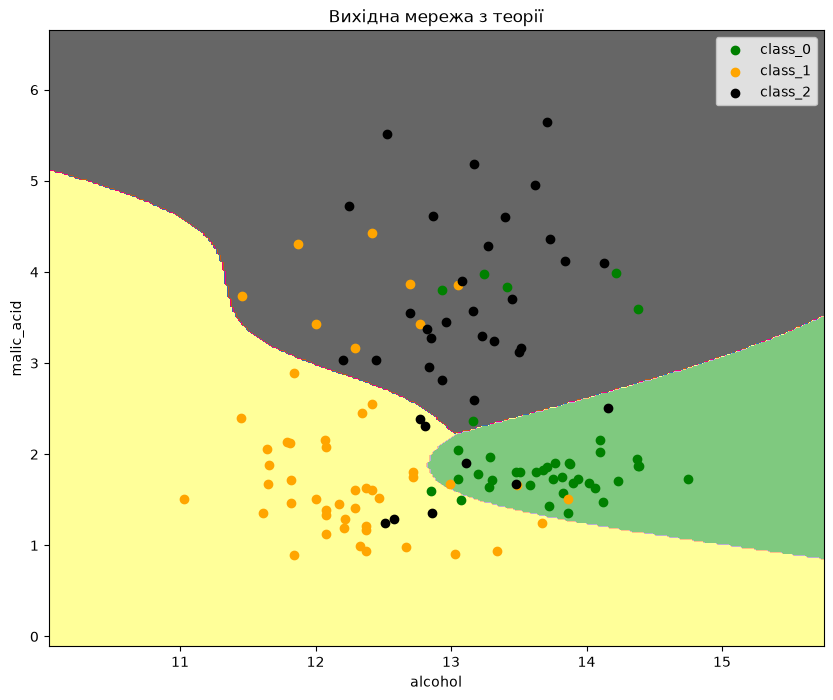

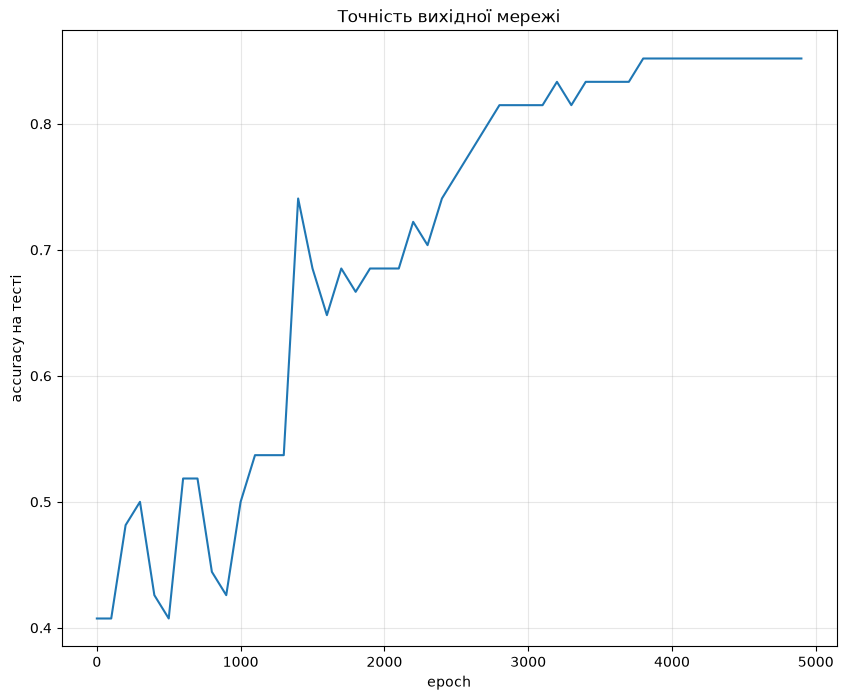

In [ ]:
def plot_decision(net, X_tr, y_tr, title):
    n_classes = 3
    plot_colors = ['g', 'orange', 'black']
    plot_step = 0.02

    X_tr = X_tr.numpy() if torch.is_tensor(X_tr) else np.asarray(X_tr)
    y_tr = y_tr.numpy() if torch.is_tensor(y_tr) else np.asarray(y_tr)

    x_min, x_max = float(X_tr[:, 0].min()) - 1, float(X_tr[:, 0].max()) + 1
    y_min, y_max = float(X_tr[:, 1].min()) - 1, float(X_tr[:, 1].max()) + 1

    xx, yy = torch.meshgrid(torch.arange(x_min, x_max, plot_step),
                            torch.arange(y_min, y_max, plot_step), indexing='ij')

    with torch.no_grad():
        preds = net.inference(torch.cat([xx.reshape(-1, 1), yy.reshape(-1, 1)], dim=1))

    preds_class = preds.data.numpy().argmax(axis=1)
    preds_class = preds_class.reshape(xx.shape)
    plt.contourf(xx, yy, preds_class, cmap='Accent')

    for i, color in zip(range(n_classes), plot_colors):
        indexes = np.where(y_tr == i)
        plt.scatter(X_tr[indexes, 0], X_tr[indexes, 1], c=color, label=wine.target_names[i])
    plt.xlabel(wine.feature_names[0])
    plt.ylabel(wine.feature_names[1])
    plt.title(title)
    plt.legend()
    plt.show()

plot_decision(wine_net, X_train, y_train, 'Вихідна мережа з теорії')

plt.plot(range(0, 5000, 100), baseline_accuracy)
plt.xlabel('epoch')
plt.ylabel('accuracy на тесті')
plt.title('Точність вихідної мережі')
plt.grid(alpha=0.3)
plt.show()

## Інструменти для експериментів

In [ ]:
def build_net(n_in, n_hidden, n_layers, activation, n_out=3):
    layers = []
    previous = n_in
    for _ in range(n_layers):
        layers.append(torch.nn.Linear(previous, n_hidden))
        layers.append(activation())
        previous = n_hidden
    layers.append(torch.nn.Linear(previous, n_out))
    return torch.nn.Sequential(*layers)

def make_optimizer(name, params, lr, weight_decay=0.0):
    if name == 'Adam':
        return torch.optim.Adam(params, lr=lr, weight_decay=weight_decay)
    if name == 'SGD':
        return torch.optim.SGD(params, lr=lr, weight_decay=weight_decay)
    if name == 'SGD + momentum':
        return torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=weight_decay)
    if name == 'SGD + Nesterov':
        return torch.optim.SGD(params, lr=lr, momentum=0.9, nesterov=True, weight_decay=weight_decay)
    if name == 'RMSprop':
        return torch.optim.RMSprop(params, lr=lr, weight_decay=weight_decay)
    if name == 'Rprop':
        return torch.optim.Rprop(params, lr=lr)
    raise ValueError(name)

def train_classifier(X_tr, y_tr, X_te, y_te, n_hidden, n_layers, activation, optimizer_name,
                    lr, epochs, batch_size, seed, weight_decay=0.0):
    torch.manual_seed(seed)
    net = build_net(X_tr.shape[1], n_hidden, n_layers, activation)
    opt = make_optimizer(optimizer_name, net.parameters(), lr, weight_decay)
    loss_fn = torch.nn.CrossEntropyLoss()

    for epoch in range(epochs):
        order = torch.randperm(len(X_tr))
        for start in range(0, len(X_tr), batch_size):
            idx = order[start:start + batch_size]
            opt.zero_grad()
            loss_fn(net(X_tr[idx]), y_tr[idx]).backward()
            opt.step()

    with torch.no_grad():
        accuracy = (net(X_te).argmax(dim=1) == y_te).float().mean().item()
    return net, accuracy

SEEDS = (0, 1, 2)
FEATURES_2 = wine.data[:, :2]
FEATURES_ALL = wine.data

def evaluate(config, features=FEATURES_2, standardize=False):
    scores = []
    for seed in SEEDS:
        X_tr, X_te, y_tr, y_te = train_test_split(features, wine.target, test_size=0.3, shuffle=True, random_state=seed)
        if standardize:
            scaler = StandardScaler().fit(X_tr)
            X_tr, X_te = scaler.transform(X_tr), scaler.transform(X_te)
        X_tr, X_te = torch.FloatTensor(X_tr), torch.FloatTensor(X_te)
        y_tr, y_te = torch.LongTensor(y_tr), torch.LongTensor(y_te)
        _, accuracy = train_classifier(X_tr, y_tr, X_te, y_te, seed=seed, **config)
        scores.append(accuracy)
    return float(np.mean(scores)), float(np.std(scores))

def run_experiment(title, variants, base, features=FEATURES_2, standardize=False):
    rows = []
    for label, change in variants.items():
        config = {**base, **change}
        mean, std = evaluate(config, features, standardize)
        rows.append({'варіант': label, 'accuracy (середнє)': mean, 'std': std, 'config': config})
    table = pd.DataFrame(rows).set_index('варіант')
    print(title)
    print(table[['accuracy (середнє)', 'std']].round(3).to_string())
    best_label = table['accuracy (середнє)'].idxmax()
    print("Найкращий варіант:", best_label)
    return table.loc[best_label, 'config'], table

base_config = dict(n_hidden=5, n_layers=2, activation=torch.nn.Sigmoid, optimizer_name='Adam',
                   lr=1e-3, epochs=600, batch_size=10)

Тестова вибірка містить лише 54 вина, тому точність дуже залежить від конкретного розбиття та ініціалізації. Щоб висновки були стійкішими, кожна конфігурація оцінюється на трьох різних розбиттях даних (з різними початковими вагами), а порівнюється середня точність. Для швидкості експерименти навчаються по 600 епох, і кожен наступний експеримент використовує найкращі налаштування з попередніх.

# Завдання 1a. Архітектура: кількість нейронів

> a) Оптимізуйте архітектуру нейронної мережі.

In [ ]:
config, table_a = run_experiment(
    'Кількість нейронів у прихованих шарах:',
    {f'{n} нейронів': {'n_hidden': n} for n in (2, 5, 10, 20, 50)},
    base_config)

Кількість нейронів у прихованих шарах:
             accuracy (середнє)    std
варіант                               
2 нейронів                0.469  0.063
5 нейронів                0.426  0.015
10 нейронів               0.611  0.159
20 нейронів               0.809  0.023
50 нейронів               0.809  0.038
Найкращий варіант: 50 нейронів


# Завдання 1b. Кількість прихованих шарів

> b) Спробуйте змінити кількість прихованих шарів

In [ ]:
config, table_b = run_experiment(
    'Кількість прихованих шарів:',
    {f'{n} шарів': {'n_layers': n} for n in (1, 2, 3, 4)},
    config)

Кількість прихованих шарів:
         accuracy (середнє)    std
варіант                           
1 шарів               0.827  0.053
2 шарів               0.809  0.038
3 шарів               0.790  0.053
4 шарів               0.821  0.023
Найкращий варіант: 1 шарів


# Завдання 1c. Оптимізатор

> c) Змінити оптимізатор.

In [ ]:
config, table_c = run_experiment(
    'Оптимізатор:',
    {name: {'optimizer_name': name} for name in ('Adam', 'SGD', 'SGD + momentum', 'SGD + Nesterov', 'RMSprop', 'Rprop')},
    config)

Оптимізатор:
                accuracy (середнє)    std
варіант                                  
Adam                         0.827  0.053
SGD                          0.432  0.031
SGD + momentum               0.660  0.117
SGD + Nesterov               0.667  0.124
RMSprop                      0.790  0.044
Rprop                        0.488  0.071
Найкращий варіант: Adam


# Завдання 1d. Швидкість навчання

> d) Змінити Learning rate.

In [ ]:
config, table_d = run_experiment(
    'Швидкість навчання:',
    {f'lr = {lr}': {'lr': lr} for lr in (1e-4, 1e-3, 1e-2, 1e-1)},
    config)

Швидкість навчання:
             accuracy (середнє)    std
варіант                               
lr = 0.0001               0.636  0.083
lr = 0.001                0.827  0.053
lr = 0.01                 0.802  0.023
lr = 0.1                  0.469  0.035
Найкращий варіант: lr = 0.001


# Завдання 1e. Функція активації

> e) Змінити функцію активації.

In [ ]:
config, table_e = run_experiment(
    'Функція активації:',
    {'Sigmoid': {'activation': torch.nn.Sigmoid}, 'Tanh': {'activation': torch.nn.Tanh},
     'ReLU': {'activation': torch.nn.ReLU}, 'LeakyReLU': {'activation': torch.nn.LeakyReLU},
     'ELU': {'activation': torch.nn.ELU}},
    config)

best_two_feature_config = dict(config)
print({k: (v.__name__ if isinstance(v, type) else v) for k, v in best_two_feature_config.items()})

Функція активації:
           accuracy (середнє)    std
варіант                             
Sigmoid                 0.827  0.053
Tanh                    0.815  0.015
ReLU                    0.796  0.040
LeakyReLU               0.802  0.044
ELU                     0.827  0.049
Найкращий варіант: ELU
{'n_hidden': 50, 'n_layers': 1, 'activation': 'ELU', 'optimizer_name': 'Adam', 'lr': 0.001, 'epochs': 600, 'batch_size': 10}


# Завдання 1f. Усі 13 ознак

> f) Спробуйте використати весь набір ознак (зараз ми використовували лише 2 ознаки для простої візуалізації)

In [ ]:
rows = []
for label, features, standardize in [
    ('2 ознаки, без нормування', FEATURES_2, False),
    ('2 ознаки, з нормуванням', FEATURES_2, True),
    ('13 ознак, без нормування', FEATURES_ALL, False),
    ('13 ознак, з нормуванням', FEATURES_ALL, True),
]:
    mean, std = evaluate(best_two_feature_config, features, standardize)
    rows.append({'варіант': label, 'accuracy (середнє)': mean, 'std': std})

table_f = pd.DataFrame(rows).set_index('варіант')
print(table_f.round(3).to_string())

                          accuracy (середнє)    std
варіант                                            
2 ознаки, без нормування               0.827  0.049
2 ознаки, з нормуванням                0.809  0.023
13 ознак, без нормування               0.944  0.015
13 ознак, з нормуванням                1.000  0.000


Ознаки вина мають дуже різний масштаб (наприклад, `proline` має значення в сотнях і тисячах, а `hue` менші за одиницю), тому для всіх 13 ознак додатково перевіряється нормування за середнім і стандартним відхиленням тренувальної вибірки.

# Завдання 1g. Інші покращення

> g) Спробуйте інші поліпшення/зміни.

In [ ]:
config_all = dict(best_two_feature_config)

config_all, table_g1 = run_experiment(
    'Розмір батча (13 ознак, з нормуванням):',
    {f'batch = {b}': {'batch_size': b} for b in (5, 10, 32)},
    config_all, FEATURES_ALL, True)

Розмір батча (13 ознак, з нормуванням):
            accuracy (середнє)  std
варіант                            
batch = 5                  1.0  0.0
batch = 10                 1.0  0.0
batch = 32                 1.0  0.0
Найкращий варіант: batch = 5


In [ ]:
config_all, table_g2 = run_experiment(
    'L2-регуляризація (weight decay):',
    {f'weight decay = {w}': {'weight_decay': w} for w in (0.0, 1e-4, 1e-3, 1e-2)},
    config_all, FEATURES_ALL, True)

L2-регуляризація (weight decay):
                       accuracy (середнє)    std
варіант                                         
weight decay = 0.0                  1.000  0.000
weight decay = 0.0001               0.994  0.009
weight decay = 0.001                1.000  0.000
weight decay = 0.01                 1.000  0.000
Найкращий варіант: weight decay = 0.0


In [ ]:
config_all, table_g3 = run_experiment(
    'Кількість епох:',
    {f'{e} епох': {'epochs': e} for e in (100, 300, 600, 1500)},
    config_all, FEATURES_ALL, True)

final_config = dict(config_all)
print({k: (v.__name__ if isinstance(v, type) else v) for k, v in final_config.items()})

Кількість епох:
           accuracy (середнє)  std
варіант                           
100 епох                  1.0  0.0
300 епох                  1.0  0.0
600 епох                  1.0  0.0
1500 епох                 1.0  0.0
Найкращий варіант: 100 епох
{'n_hidden': 50, 'n_layers': 1, 'activation': 'ELU', 'optimizer_name': 'Adam', 'lr': 0.001, 'epochs': 100, 'batch_size': 5, 'weight_decay': 0.0}


## Порівняння вихідної та покращеної мережі

                                               accuracy (середнє)    std
модель                                                                  
вихідна мережа, 600 епох (як в експериментах)               0.426  0.015
вихідна мережа, 5000 епох (як в теорії)                     0.815  0.015
покращена мережа (2 ознаки)                                 0.827  0.049
покращена мережа (13 ознак, нормування)                     1.000  0.000


Точність найкращої мережі на 2 ознаках (розбиття 0): 0.87


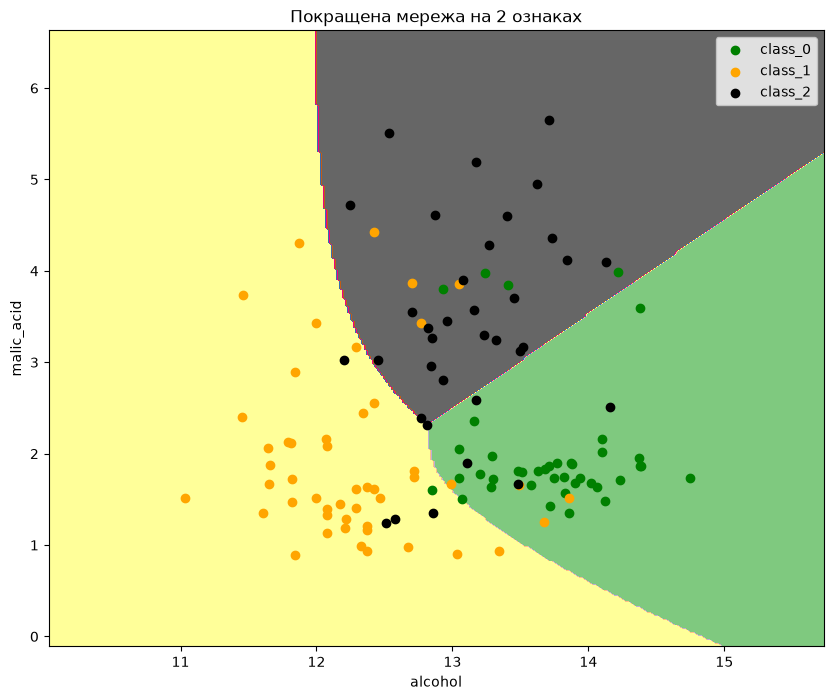

In [ ]:
rows = []
for label, cfg, features, standardize in [
    ('вихідна мережа, 600 епох (як в експериментах)', base_config, FEATURES_2, False),
    ('вихідна мережа, 5000 епох (як в теорії)', {**base_config, 'epochs': 5000}, FEATURES_2, False),
    ('покращена мережа (2 ознаки)', best_two_feature_config, FEATURES_2, False),
    ('покращена мережа (13 ознак, нормування)', final_config, FEATURES_ALL, True),
]:
    mean, std = evaluate(cfg, features, standardize)
    rows.append({'модель': label, 'accuracy (середнє)': mean, 'std': std})

table_final = pd.DataFrame(rows).set_index('модель')
print(table_final.round(3).to_string())

X_tr, X_te, y_tr, y_te = train_test_split(FEATURES_2, wine.target, test_size=0.3, shuffle=True, random_state=0)
X_tr_t, X_te_t = torch.FloatTensor(X_tr), torch.FloatTensor(X_te)
best_net_2, best_acc_2 = train_classifier(X_tr_t, torch.LongTensor(y_tr), X_te_t, torch.LongTensor(y_te),
                                         seed=0, **best_two_feature_config)

class SoftmaxWrapper(torch.nn.Module):
    def __init__(self, net):
        super().__init__()
        self.net = net

    def inference(self, x):
        return torch.softmax(self.net(x), dim=1)

print("Точність найкращої мережі на 2 ознаках (розбиття 0):", round(best_acc_2, 3))
plot_decision(SoftmaxWrapper(best_net_2), X_tr, y_tr, 'Покращена мережа на 2 ознаках')

**Аналіз результатів експериментів.** Вихідна мережа з теорії (2 ознаки, два шари по 5 нейронів із сигмоїдою, Adam 1e-3) після 5000 епох дає точність приблизно 0.82 на тесті (на одному розбитті 0.85, а в середньому за трьома розбиттями див. таблицю вище). Експерименти a–e проводились на тих самих двох ознаках по 600 епох.

- **Кількість нейронів (a).** Малі мережі не встигають навчитись за 600 епох зі швидкістю 1e-3: з 2, 5 і 10 нейронами середня точність становить 0.47, 0.43 і 0.61, а з 20 і 50 нейронами 0.81. Більше нейронів дають більшу ємність і швидше підлаштовуються, тому для подальших експериментів обрано 50.
- **Кількість шарів (b).** Один шар дав 0.827, два 0.809, три 0.790, чотири 0.821. Різниці менші за розкид між розбиттями (стандартне відхилення 0.02–0.05), тобто додаткові шари нічого не покращили, а для двох ознак достатньо одного прихованого шару.
- **Оптимізатор (c).** Найкращим виявився Adam (0.827), трохи гірший RMSprop (0.790). Звичайний SGD зі швидкістю 1e-3 за 600 епох майже не навчився (0.432), момент (0.660) і момент Нестерова (0.667) допомагають, але не наздоганяють Adam, а Rprop дав 0.488. Adam адаптує розмір кроку для кожного параметра, що важливо, бо ознаки `alcohol` і `malic_acid` мають різний масштаб.
- **Швидкість навчання (d).** Найкращою була 1e-3 (0.827), а 1e-2 дала 0.802. Дуже мала швидкість 1e-4 не встигає навчити мережу (0.636), а дуже велика 0.1 робить навчання нестабільним (0.469).
- **Функція активації (e).** Sigmoid і ELU дали по 0.827, Tanh 0.815, LeakyReLU 0.802, ReLU 0.796. Різниця лежить у межах похибки, тому вибір активації майже не впливає на результат. За незначною перевагою обрано ELU.
- **Усі ознаки (f).** Це найбільше покращення. З усіма 13 ознаками без нормування точність становить 0.944, а з нормуванням 1.000. На двох ознаках нормування не допомагає (0.809 проти 0.827), бо вони мають близький масштаб. На 13 ознаках нормування потрібне, бо `proline` має значення в сотнях і тисячах і домінує над ознаками з малими значеннями.
- **Інші покращення (g).** Розмір батча (5, 10, 32), L2-регуляризація та кількість епох (від 100 до 1500) уже не змінюють точність: скрізь 1.000, окрім одного випадку 0.994. Тому найпростіші значення (100 епох) вважаються достатніми. Через те, що точність досягла 100% на малій тестовій вибірці, ці параметри на ній не розрізняються.

**Підсумок порівняння.** Вихідна мережа на двох ознаках дає приблизно 0.82 після 5000 епох. Покращена мережа на двох ознаках дає схожі 0.83, але вже після 600 епох, тобто налаштування прискорили навчання, але стеля точності на двох ознаках обмежена самими ознаками. Основний виграш дали усі 13 ознаки з нормуванням: точність 1.000 при 100 епохах. На рисунку межі рішень для двох ознак видно, що класи значною мірою перекриваються, тому на двох ознаках їх повністю розділити неможливо.

# Завдання 2. Breast Cancer Wisconsin

> Проаналізуйте тренувальний датасет Breast Cancer Wisconsin (https://archive.ics.uci.edu/ml/datasets/Breast+Cancer+Wisconsin+(Diagnostic)) та розробіть модель класифікації (класифікація пухлини – колонка таргету – Diagnosis (M = malignant(злоякісна), B = benign (доброякісна))). Цей датасет також можна знайти в бібліотеці sklearn:
>
> `from sklearn.datasets import load_breast_cancer`
>
> `data = load_breast_cancer()`
>
> `X, y = data.data, data.target`

## Аналіз даних

In [ ]:
data = load_breast_cancer()
X, y = data.data, data.target

cancer = pd.DataFrame(X, columns=data.feature_names)
cancer['target'] = y

print(cancer.shape)
print(data.target_names, "-> 0 це", data.target_names[0], ", 1 це", data.target_names[1])
print(cancer['target'].value_counts().rename({0: 'malignant', 1: 'benign'}).to_string())
print("Пропущених значень:", cancer.isna().sum().sum())
print(cancer.iloc[:, :5].describe().round(2).to_string())

(569, 31)
['malignant' 'benign'] -> 0 це malignant , 1 це benign
target
benign       357
malignant    212
Пропущених значень: 0
       mean radius  mean texture  mean perimeter  mean area  mean smoothness
count       569.00        569.00          569.00     569.00           569.00
mean         14.13         19.29           91.97     654.89             0.10
std           3.52          4.30           24.30     351.91             0.01
min           6.98          9.71           43.79     143.50             0.05
25%          11.70         16.17           75.17     420.30             0.09
50%          13.37         18.84           86.24     551.10             0.10
75%          15.78         21.80          104.10     782.70             0.11
max          28.11         39.28          188.50    2501.00             0.16


У `sklearn` клас `0` відповідає злоякісній пухлині (malignant), а клас `1` доброякісній (benign). Датасет містить 569 пацієнтів і 30 числових ознак, які описують ядра клітин (радіус, текстура, периметр, площа, гладкість тощо, по три статистики: середнє, стандартна похибка та найгірше значення).

Найсильніше пов'язані з діагнозом ознаки:
worst concave points   -0.794
worst perimeter        -0.783
mean concave points    -0.777
worst radius           -0.776
mean perimeter         -0.743
worst area             -0.734
mean radius            -0.730
mean area              -0.709


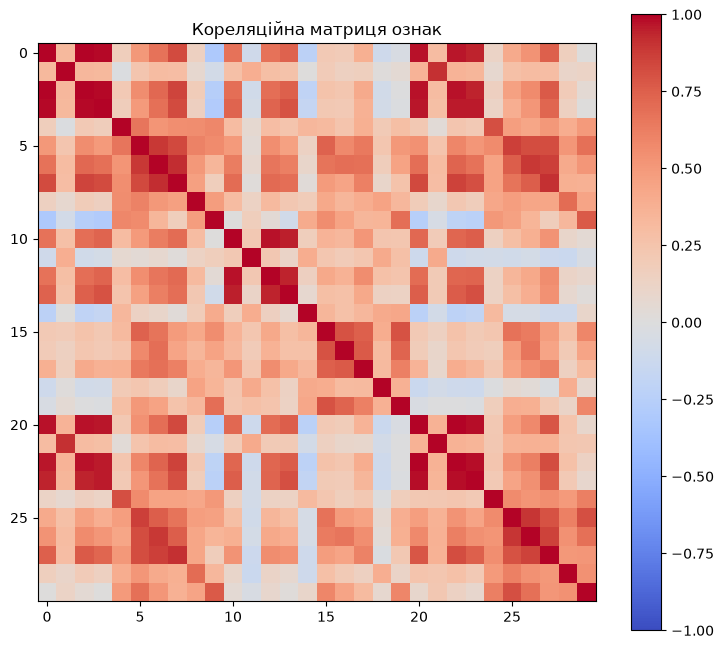

In [ ]:
corr_with_target = cancer.corr()['target'].drop('target').sort_values(key=abs, ascending=False)
print("Найсильніше пов'язані з діагнозом ознаки:")
print(corr_with_target.head(8).round(3).to_string())

corr_matrix = cancer.drop(columns='target').corr()
plt.figure(figsize=(9, 8))
plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()
plt.title('Кореляційна матриця ознак')
plt.show()

## Видалення сильно корельованих ознак

In [ ]:
THRESHOLD = 0.9

abs_corr = corr_matrix.abs()
upper = abs_corr.where(np.triu(np.ones(abs_corr.shape), k=1).astype(bool))
to_drop = [column for column in upper.columns if (upper[column] > THRESHOLD).any()]
kept = [c for c in corr_matrix.columns if c not in to_drop]

pairs = (upper.stack().loc[lambda s: s > THRESHOLD].sort_values(ascending=False))
print("Пар ознак з |r| >", THRESHOLD, ":", len(pairs))
print(pairs.head(8).round(3).to_string())
print()
print("Видаляємо", len(to_drop), "ознак:", to_drop)
print("Залишається", len(kept), "ознак:", kept)

Пар ознак з |r| > 0.9 : 21
mean radius      mean perimeter     0.998
worst radius     worst perimeter    0.994
mean radius      mean area          0.987
mean perimeter   mean area          0.987
worst radius     worst area         0.984
worst perimeter  worst area         0.978
radius error     perimeter error    0.973
mean perimeter   worst perimeter    0.970

Видаляємо 10 ознак: ['mean perimeter', 'mean area', 'mean concave points', 'perimeter error', 'area error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst concave points']
Залишається 20 ознак: ['mean radius', 'mean texture', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst symmetry', 'worst fractal dimension']


Для кожної пари ознак із коефіцієнтом кореляції Пірсона за модулем більше за 0.9 видаляється одна з двох (та, що стоїть у таблиці пізніше). Тим самим усуваються дублюючі одна одну ознаки, як-от радіус, периметр і площа, які майже однозначно виражаються одна через одну.

## Навчання моделі

In [ ]:
def make_loaders(columns, seed):
    features = cancer[columns].values
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(features, y, test_size=0.4, stratify=y, random_state=seed)
    X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=seed)
    scaler = StandardScaler().fit(X_tr)
    tensors = []
    for part_X, part_y in ((X_tr, y_tr), (X_va, y_va), (X_te, y_te)):
        tensors.append((torch.FloatTensor(scaler.transform(part_X)), torch.LongTensor(part_y)))
    return tensors

def train_cancer(columns, n_hidden, seed, epochs=200, lr=1e-3, batch_size=32):
    (X_tr, y_tr), (X_va, y_va), (X_te, y_te) = make_loaders(columns, seed)
    torch.manual_seed(seed)
    net = build_net(len(columns), n_hidden, 2, torch.nn.ReLU, n_out=2)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    loss_fn = torch.nn.CrossEntropyLoss()

    best_val, best_state = -1.0, None
    train_loss, val_acc = [], []
    for epoch in range(epochs):
        order = torch.randperm(len(X_tr))
        epoch_loss = 0.0
        for start in range(0, len(X_tr), batch_size):
            idx = order[start:start + batch_size]
            opt.zero_grad()
            loss_value = loss_fn(net(X_tr[idx]), y_tr[idx])
            loss_value.backward()
            opt.step()
            epoch_loss += loss_value.item() * len(idx)
        train_loss.append(epoch_loss / len(X_tr))

        with torch.no_grad():
            acc = (net(X_va).argmax(dim=1) == y_va).float().mean().item()
        val_acc.append(acc)
        if acc > best_val:
            best_val = acc
            best_state = {k: v.clone() for k, v in net.state_dict().items()}

    net.load_state_dict(best_state)
    with torch.no_grad():
        test_pred = net(X_te).argmax(dim=1)
    return net, y_te, test_pred, train_loss, val_acc, best_val

rows = []
for n_hidden in (8, 16, 32):
    val_scores = []
    for seed in (0, 1, 2):
        _, _, _, _, _, best_val = train_cancer(kept, n_hidden, seed)
        val_scores.append(best_val)
    rows.append({'нейронів у шарі': n_hidden, 'validation accuracy (середнє)': np.mean(val_scores)})

architecture_table = pd.DataFrame(rows).set_index('нейронів у шарі')
print(architecture_table.round(4).to_string())

best_hidden = int(architecture_table['validation accuracy (середнє)'].idxmax())
print("Обрано нейронів у шарі:", best_hidden)

                 validation accuracy (середнє)
нейронів у шарі                               
8                                       0.9561
16                                      0.9649
32                                      0.9678
Обрано нейронів у шарі: 32


Мережа має два приховані шари з активацією ReLU та два виходи (за кількістю класів). Дані діляться на тренувальну, валідаційну та тестову вибірки у співвідношенні 60 / 20 / 20 із збереженням пропорції класів, а ознаки нормуються за тренувальною вибіркою. Кількість нейронів обирається за валідацією, ваги зберігаються на епосі з найкращою валідаційною точністю, а тест використовується для фінальної оцінки.

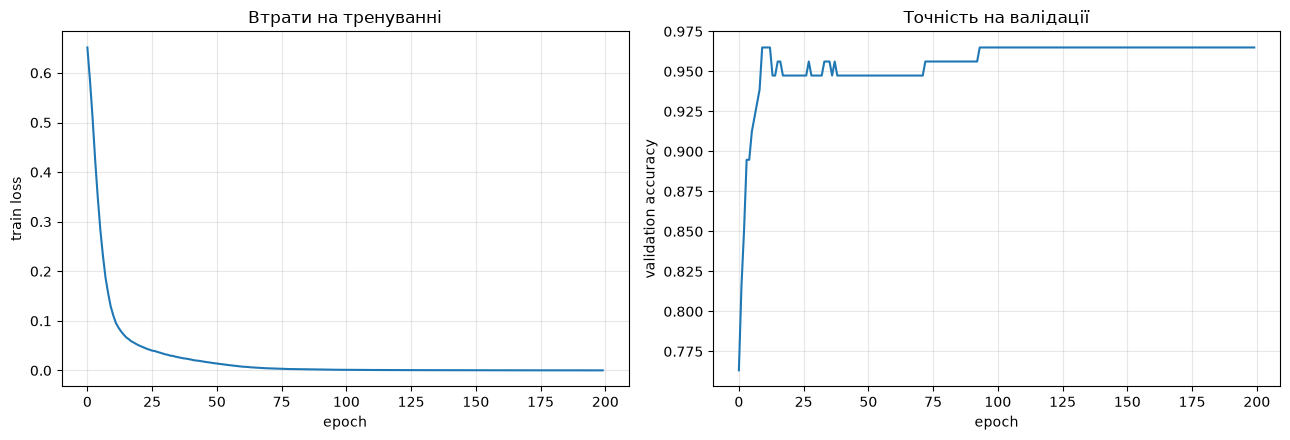

Accuracy на тесті: 0.9649
Матриця помилок (рядки - факт, стовпці - прогноз; 0 = malignant, 1 = benign):
[[41  2]
 [ 2 69]]
              precision    recall  f1-score   support

   malignant     0.9535    0.9535    0.9535        43
      benign     0.9718    0.9718    0.9718        71

    accuracy                         0.9649       114
   macro avg     0.9627    0.9627    0.9627       114
weighted avg     0.9649    0.9649    0.9649       114



In [ ]:
net, y_te, test_pred, train_loss, val_acc, best_val = train_cancer(kept, best_hidden, seed=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(train_loss)
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('train loss')
axes[0].set_title('Втрати на тренуванні')
axes[0].grid(alpha=0.3)
axes[1].plot(val_acc)
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('validation accuracy')
axes[1].set_title('Точність на валідації')
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Accuracy на тесті:", round(accuracy_score(y_te, test_pred), 4))
print("Матриця помилок (рядки - факт, стовпці - прогноз; 0 = malignant, 1 = benign):")
print(confusion_matrix(y_te, test_pred))
print(classification_report(y_te, test_pred, target_names=['malignant', 'benign'], digits=4))

## Вплив видалення корельованих ознак

In [ ]:
rows = []
for label, columns in (('усі 30 ознак', list(corr_matrix.columns)), (f'{len(kept)} ознак (без |r| > 0.9)', kept)):
    accuracies, recalls = [], []
    for seed in range(5):
        _, y_true, y_pred, _, _, _ = train_cancer(columns, best_hidden, seed)
        accuracies.append(accuracy_score(y_true, y_pred))
        malignant = (y_true == 0)
        recalls.append(((y_pred == 0) & malignant).sum().item() / malignant.sum().item())
    rows.append({'набір ознак': label, 'accuracy (середнє)': np.mean(accuracies), 'std': np.std(accuracies),
                 'recall malignant (середнє)': np.mean(recalls)})

comparison = pd.DataFrame(rows).set_index('набір ознак')
print(comparison.round(4).to_string())

                          accuracy (середнє)     std  recall malignant (середнє)
набір ознак                                                                     
усі 30 ознак                          0.9789  0.0070                      0.9721
20 ознак (без |r| > 0.9)              0.9719  0.0035                      0.9532


**Аналіз результатів.** Набір містить 569 пацієнтів (357 доброякісних і 212 злоякісних пухлин) і 30 ознак без пропусків. З діагнозом найсильніше пов'язані ознаки, що описують розмір і форму ядра: `worst concave points` (-0.79), `worst perimeter` (-0.78), `mean concave points` (-0.78) та `worst radius` (-0.78). Знак мінус означає, що більші значення відповідають класу 0, тобто злоякісній пухлині.

Ознаки сильно корельовані між собою: знайдено 21 пару з коефіцієнтом Пірсона за модулем більше за 0.9, наприклад `mean radius` та `mean perimeter` (0.998). Це дублюючі виміри розміру ядра. Після видалення 10 ознак (`mean perimeter`, `mean area`, `mean concave points`, `perimeter error`, `area error`, `worst radius`, `worst texture`, `worst perimeter`, `worst area`, `worst concave points`) лишилось 20 ознак.

Нейромережа з двома прихованими шарами по 32 нейрони (кількість обрана за валідацією) на тестовій вибірці з 114 пацієнтів досягла точності 0.965. Матриця помилок: із 43 злоякісних пухлин правильно визначено 41, а з 71 доброякісних правильно 69, тобто по дві помилки в кожному класі. Precision, recall та F1 для злоякісного класу дорівнюють 0.954, а для доброякісного 0.972.

Для порівняння виконано п'ять запусків із різними розбиттями. На всіх 30 ознаках середня точність становить 0.979, а на 20 ознаках після видалення корельованих 0.972, при цьому частка знайдених злоякісних пухлин (recall) 0.972 проти 0.953. Різниця невелика і близька до розкиду між запусками (стандартне відхилення 0.004–0.007), тобто видалення третини ознак майже не погіршує якість, а модель стає простішою.

# Висновки

У цьому практикумі ми навчились будувати нейронну мережу для задачі класифікації в PyTorch: готувати дані та розбивати їх на тренувальну й тестову частини, навчати мережу по батчах, використовувати крос-ентропію, оцінювати точність через `argmax` виходів та покращувати мережу, змінюючи її архітектуру й параметри навчання. Метою завдання було засвоїти принцип роботи та способи побудови нейронної мережі для задачі класифікації, і її досягнуто.

**Обрана конфігурація для класифікації вин.** Найкращою виявилась мережа з одним прихованим шаром на 50 нейронів та активацією ELU, оптимізатор Adam зі швидкістю навчання 1e-3, батчі по 5 елементів, без регуляризації та 100 епох навчання. Вона використовує всі 13 ознак, нормованих за середнім і стандартним відхиленням тренувальної вибірки, і дає на тесті точність 1.000. Вихідна мережа з теорії на двох ознаках дає лише близько 0.82. Отже, найбільше результат покращило використання всіх ознак із нормуванням, тоді як зміна оптимізатора та швидкості навчання (Adam, 1e-3) відіграла роль скоріше в тому, щоб мережа взагалі встигла навчитись, а кількість шарів і функція активації практично не вплинули. Слід враховувати, що тестова вибірка містить лише 54 вина, тому точність 1.000 не розрізняє близькі налаштування.

**Класифікація пухлин (Breast Cancer Wisconsin).** З 30 ознак за порогом кореляції Пірсона 0.9 видалено 10 надлишкових ознак, переважно дублюючих вимірів розміру ядра (радіус, периметр, площа). Мережа з двома прихованими шарами по 32 нейрони на 20 ознаках має точність 0.965 на тесті (по дві помилки на клас) і середню точність 0.972 за п'ятьма запусками, що лише трохи поступається 0.979 на всіх 30 ознаках. Видалення сильно корельованих ознак спрощує модель майже без втрати якості, але для медичної задачі варто стежити за повнотою знаходження злоякісних пухлин (recall 0.953 проти 0.972 на всіх ознаках).

# Контрольні питання

**1. У чому суть задачі класифікації?**

У задачі класифікації потрібно за ознаками об'єкта визначити, до якого з відомих класів він належить. Наприклад, за 13 хімічними параметрами пляшки визначити один із трьох сортів вина або за ознаками клітин визначити, чи пухлина злоякісна, чи доброякісна. Відповіддю є не довільне число, а номер класу. Для цього модель навчається на розмічених прикладах, а якість перевіряється на тестових даних, яких вона не бачила, найчастіше як частка правильно передбачених класів.

**2. Чим принципово відрізняється нейронна мережа для задачі регресії та класифікації?**

Мережа для регресії передбачає дійсне число, тому її останній шар має один нейрон без активації, а втрата це середня квадратична помилка. Мережа для класифікації на виході має стільки нейронів, скільки класів, і кожен нейрон відповідає за свій клас. Ці виходи за допомогою softmax можна перетворити на ймовірності класів, а втратою є крос-ентропія. Під час навчання softmax не обчислюється окремо, бо `torch.nn.CrossEntropyLoss` приймає виходи мережі без softmax, а клас передбачається як індекс найбільшого виходу (`argmax`). Тип цілей теж різний: у регресії це числа з плаваючою комою, а в класифікації це цілі номери класів (`LongTensor`). Якість у регресії міряють помилкою (MSE), а в класифікації часткою правильних відповідей (accuracy).